# 04. Machine Learning on Fixed-Cutoff Features (PySpark MLlib)

**Module:** 7COM2005 - Data Engineering, University of Hertfordshire

**Input:** `data/processed/customer_churn_dataset_cutoff14.parquet`, built by `03_Fixed_Cutoff_Features.ipynb`.
Each feature uses only events before `start_date + 14 days`. This notebook is the **leakage-controlled** version of `02_Machine_Learning.ipynb`, which used the full-window canonical features.

**Target:** `churn_label = 1 - auto_renew`. Positive class = churn (did not renew). The label is the outcome observed at the end of the subscription. It is a proxy, not verified cancellation.

**Environment:** Python 3.12, PySpark 4.3.0, pandas 2.3.x. All modelling uses PySpark MLlib.

## Design decisions

| Decision | Choice | Why |
|---|---|---|
| Features | Fixed-cutoff features only | The ETL features are aggregated only up to `start + 14 days`, so they can be known at that point. |
| Excluded | `duration_days`, review features, `has_reviews` | Duration is constant (14) and carries no information. Reviews have no dates, so they cannot be placed before the cutoff. |
| Configurations | A = operational; B = operational + survey | Same as notebook 02. The sensitivity run (S) is dropped because the cutoff already removes the leakage it tested. |
| Split | Exact stratified 80/20, seed 42 | Same as notebook 02, so the two results are comparable. |
| Missing rates | Rates undefined without events (e.g. average order value for customers with no orders) stay missing and are imputed with the training-fold median | Missing is not the same as zero, so these are not filled with 0. |
| Model selection | 3-fold CV AUC among A and B | Test data is not used for choosing parameters. |
| Survey | Configuration B only, timing caveat | The survey has no timestamp, so it may be after the cutoff. |

## Verified findings

1. The cutoff dataset is built by the **unchanged** ETL feature functions run on filtered inputs. Run on the unfiltered data, the same functions reproduce the canonical Parquet exactly (35 of 35 comparable columns), so the reuse is faithful.
2. No order or web session in the cutoff inputs falls at or after the cutoff.
3. Across the 221 customers, 0 have no orders in the first 14 days. 78 have no CRM interaction in that window.
4. Mean features in the first 14 days are roughly 6 to 12% of the canonical full-window means for counts and totals, as expected from the shorter window.
5. In the first 14 days churned customers average **more** orders than renewed ones (14.3 against 12.3). This does not match the full-window pattern and is reported as found.

## Assumptions and remaining limits

- **A. Survey timing:** the survey has no timestamp. Configuration B may use answers given after the cutoff. Treat B as a sensitivity result, not a clean pre-cutoff model.
- **B. Cutoff choice:** 14 days was chosen before looking at model results. Sensitivity to 21 days was not run.
- **C. Outcome proxy:** `auto_renew = 0` is treated as churn and has not been checked against cancellation records.
- **D. Sample size:** 221 customers and a 44-customer test set. Differences of one or two customers are noise.

## 1. Environment and Spark session

In [1]:
import os, sys
from pathlib import Path

os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pyspark.sql import SparkSession, Window, functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, Imputer, VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier, GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator
from pyspark.ml.functions import vector_to_array

SEED = 42
TRAIN_FRACTION = 0.8
N_FOLDS = 3
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)

def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for cand in [start, *start.parents]:
        if (cand / "data/processed/customer_churn_dataset_cutoff14.parquet").exists():
            return cand
        if (cand / "PerfectPetClub/data/processed/customer_churn_dataset_cutoff14.parquet").exists():
            return cand / "PerfectPetClub"
    raise FileNotFoundError("cutoff14 Parquet not found from " + str(start))

PROJECT = find_project_root()
PARQUET_PATH = PROJECT / "data/processed/customer_churn_dataset_cutoff14.parquet"
OUTPUT_DIR = PROJECT / "outputs/ml_cutoff14"
MODEL_DIR = PROJECT / "models/cutoff14"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

spark = (SparkSession.builder.master("local[*]").appName("PerfectPetClub-ML-cutoff14")
         .config("spark.driver.memory", "2g")
         .config("spark.sql.shuffle.partitions", "8")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Python:", sys.version.split()[0], "| Spark:", spark.version)
print("Dataset:", PARQUET_PATH)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/15 23:46:41 WARN Utils: Your hostname, ATCHYUTHs-MacBook-Air.local, resolves to a loopback address: 127.0.0.1; using 192.168.0.63 instead (on interface en0)
26/11/15 23:46:41 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/15 23:46:41 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Python: 3.12.7 | Spark: 4.3.0
Dataset: /Users/atchyuthkarri/7COM2005-Data-Engineering/PerfectPetClub/data/processed/customer_churn_dataset_cutoff14.parquet


## 2. Load and inspect

In [2]:
CATEGORICAL_OPS = ["subscription_tier", "delivery_service"]
NUMERIC_OPS = [
    "total_orders", "total_spend_pence", "avg_order_value_pence",
    "total_items_purchased", "unique_products_purchased", "avg_items_per_order",
    "completed_deliveries", "unfulfilled_orders", "delayed_deliveries",
    "avg_delivery_delay_hours", "delivery_delay_ratio",
    "total_crm_interactions", "crm_complaints_count", "crm_queries_count",
    "crm_email_count", "crm_phone_count", "crm_livechat_count", "crm_complaint_ratio",
    "total_web_sessions", "days_since_last_session",
    "session_frequency_per_month", "order_frequency_per_month",
]
CATEGORICAL_SURVEY = ["reported_income"]
NUMERIC_SURVEY = ["nps_recommend", "satisfaction_score", "online_comparison_freq"]

raw = spark.read.parquet(str(PARQUET_PATH))
print("Rows:", raw.count(), "| Columns:", len(raw.columns))
raw.printSchema()
print("customer_id unique:", raw.select("customer_id").distinct().count() == raw.count())
raw.groupBy("auto_renew").count().orderBy("auto_renew").show()
print("Leakage-prone columns present (must be absent):",
      [c for c in ["duration_days", "avg_star_rating", "has_reviews", "total_reviews"] if c in raw.columns])

Rows: 221 | Columns: 30
root
 |-- customer_id: long (nullable = true)
 |-- subscription_tier: string (nullable = true)
 |-- delivery_service: string (nullable = true)
 |-- auto_renew: long (nullable = true)
 |-- total_orders: long (nullable = true)
 |-- total_spend_pence: long (nullable = true)
 |-- avg_order_value_pence: double (nullable = true)
 |-- total_items_purchased: long (nullable = true)
 |-- unique_products_purchased: long (nullable = true)
 |-- avg_items_per_order: double (nullable = true)
 |-- completed_deliveries: long (nullable = true)
 |-- unfulfilled_orders: long (nullable = true)
 |-- delayed_deliveries: long (nullable = true)
 |-- avg_delivery_delay_hours: double (nullable = true)
 |-- delivery_delay_ratio: double (nullable = true)
 |-- total_crm_interactions: double (nullable = true)
 |-- crm_complaints_count: double (nullable = true)
 |-- crm_queries_count: double (nullable = true)
 |-- crm_email_count: double (nullable = true)
 |-- crm_phone_count: double (nullable

customer_id unique: True
+----------+-----+
|auto_renew|count|
+----------+-----+
|         0|   86|
|         1|  135|
+----------+-----+

Leakage-prone columns present (must be absent): []


## 3. Target and cleaning

`churn_label = 1 - auto_renew`. Numeric columns are cast to double for the imputer. Missing rates (NaN) are kept as missing and imputed later from training data.

In [3]:
ALL_NUMERIC = sorted(set(NUMERIC_OPS + NUMERIC_SURVEY))
df = raw.withColumn("churn_label", (F.lit(1) - F.col("auto_renew")).cast("double"))
for c in ALL_NUMERIC:
    df = df.withColumn(c, F.col(c).cast("double"))
# Treat NaN as null so the imputer treats both the same way.
df = df.select(*[F.when(F.isnan(F.col(c)), None).otherwise(F.col(c)).alias(c) if c in ALL_NUMERIC else F.col(c)
                 for c in df.columns]).cache()
print("Missing values per feature (after NaN -> null):")
miss = {c: df.filter(F.col(c).isNull()).count() for c in ALL_NUMERIC}
print({k: v for k, v in miss.items() if v})
df.groupBy("churn_label").count().orderBy("churn_label").show()

Missing values per feature (after NaN -> null):


{}
+-----------+-----+
|churn_label|count|
+-----------+-----+
|        0.0|  135|
|        1.0|   86|
+-----------+-----+



### 3a. Survey check

The survey file has no nulls and every score is on the 0-10 scale. Zeros are kept as valid answers (assumption A in notebook 02).

In [4]:
for c in NUMERIC_SURVEY:
    print(f"{c:24s} zeros={df.filter(F.col(c) == 0).count():3d}  nulls={df.filter(F.col(c).isNull()).count()}")

nps_recommend            zeros=  2  nulls=0
satisfaction_score       zeros= 29  nulls=0
online_comparison_freq   zeros=  1  nulls=0


## 4. Feature configurations

In [5]:
CONFIGS = {
    "A_cutoff_operational": {"cat": CATEGORICAL_OPS, "num": NUMERIC_OPS},
    "B_cutoff_operational_plus_survey": {"cat": CATEGORICAL_OPS + CATEGORICAL_SURVEY, "num": NUMERIC_OPS + NUMERIC_SURVEY},
}
for name, cfg in CONFIGS.items():
    missing = [c for c in cfg["cat"] + cfg["num"] if c not in df.columns]
    assert not missing, f"{name} missing columns: {missing}"
    print(f"{name:34s} categorical={len(cfg['cat'])}  numeric={len(cfg['num'])}")

A_cutoff_operational               categorical=2  numeric=22
B_cutoff_operational_plus_survey   categorical=3  numeric=25


## 5. Stratified 80/20 split (seed 42)

In [6]:
counts = {int(r["churn_label"]): r["count"] for r in df.groupBy("churn_label").count().collect()}
cutoffs = {label: int(round(n * TRAIN_FRACTION)) for label, n in counts.items()}

w = Window.partitionBy("churn_label").orderBy(F.rand(SEED))
ranked = (df.coalesce(1)
            .withColumn("rn", F.row_number().over(w))
            .withColumn("split", F.when(F.col("rn") <= F.when(F.col("churn_label") == 1.0, cutoffs[1]).otherwise(cutoffs[0]), "train").otherwise("test"))
            .cache())
ranked.count()
train_df = ranked.filter(F.col("split") == "train").drop("rn", "split").cache()
test_df = ranked.filter(F.col("split") == "test").drop("rn", "split").cache()
n_train, n_test = train_df.count(), test_df.count()
overlap = train_df.select("customer_id").intersect(test_df.select("customer_id")).count()
print(f"Train rows: {n_train} | Test rows: {n_test} | Overlapping customer_ids: {overlap}")

def class_counts(d):
    return d.groupBy("churn_label").count().toPandas().set_index("churn_label")["count"]

split_table = pd.DataFrame({"train": class_counts(train_df), "test": class_counts(test_df)})
split_table.index = ["Renewed (0)", "Churned (1)"]
split_table["train_%"] = (100 * split_table["train"] / split_table["train"].sum()).round(1)
split_table["test_%"] = (100 * split_table["test"] / split_table["test"].sum()).round(1)
display(split_table)

# Save the split so the dashboard evaluates on exactly these held-out customers.
split_ids = (ranked.select("customer_id", "churn_label", "split").toPandas())
split_ids.to_csv(OUTPUT_DIR / "split_customer_ids.csv", index=False)

Train rows: 177 | Test rows: 44 | Overlapping customer_ids: 0


,train,test,train_%,test_%
Renewed (0),108,27,61.0,61.4
Churned (1),69,17,39.0,38.6


## 6. Pipelines, models and grids

In [7]:
def build_pipeline(cat_cols, num_cols, classifier):
    stages = []
    for c in cat_cols:
        stages.append(StringIndexer(inputCol=c, outputCol=f"{c}_idx", handleInvalid="keep"))
    if cat_cols:
        stages.append(OneHotEncoder(
            inputCols=[f"{c}_idx" for c in cat_cols],
            outputCols=[f"{c}_ohe" for c in cat_cols],
            handleInvalid="keep"))
    stages.append(Imputer(inputCols=num_cols, outputCols=[f"{c}_imp" for c in num_cols], strategy="median"))
    stages.append(VectorAssembler(
        inputCols=[f"{c}_imp" for c in num_cols] + [f"{c}_ohe" for c in cat_cols],
        outputCol="features_raw", handleInvalid="keep"))
    stages.append(StandardScaler(inputCol="features_raw", outputCol="features", withMean=False, withStd=True))
    stages.append(classifier)
    return Pipeline(stages=stages)

def make_models():
    lr = LogisticRegression(labelCol="churn_label", featuresCol="features", maxIter=200)
    rf = RandomForestClassifier(labelCol="churn_label", featuresCol="features", numTrees=200, seed=SEED)
    gbt = GBTClassifier(labelCol="churn_label", featuresCol="features", seed=SEED)
    return {
        "LogisticRegression": (lr, ParamGridBuilder()
            .addGrid(lr.regParam, [0.01, 0.1, 1.0])
            .addGrid(lr.elasticNetParam, [0.0, 0.5]).build()),
        "RandomForest": (rf, ParamGridBuilder()
            .addGrid(rf.maxDepth, [3, 5])
            .addGrid(rf.minInstancesPerNode, [1, 5]).build()),
        "GBTClassifier": (gbt, ParamGridBuilder()
            .addGrid(gbt.maxDepth, [2, 3])
            .addGrid(gbt.maxIter, [20, 50]).build()),
    }

## 7. Cross-validated training and held-out evaluation

In [8]:
auc_eval = BinaryClassificationEvaluator(labelCol="churn_label", rawPredictionCol="rawPrediction", metricName="areaUnderROC")

def confusion_and_metrics(pred):
    rows = pred.groupBy("churn_label", "prediction").count().collect()
    cm = {(int(r["churn_label"]), int(r["prediction"])): int(r["count"]) for r in rows}
    tn, fp = cm.get((0, 0), 0), cm.get((0, 1), 0)
    fn, tp = cm.get((1, 0), 0), cm.get((1, 1), 0)
    n = tn + fp + fn + tp
    precision = tp / (tp + fp) if (tp + fp) else float("nan")
    recall = tp / (tp + fn) if (tp + fn) else float("nan")
    f1 = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else float("nan")
    return {"accuracy": (tp + tn) / n, "churn_precision": precision, "churn_recall": recall,
            "churn_f1": f1, "roc_auc": auc_eval.evaluate(pred), "TN": tn, "FP": fp, "FN": fn, "TP": tp}

def param_dict(param_map):
    return {p.name: v for p, v in param_map.items()}

results, fitted = [], {}
for cfg_name, cfg in CONFIGS.items():
    for model_name, (estimator, grid) in make_models().items():
        pipe = build_pipeline(cfg["cat"], cfg["num"], estimator)
        cv = CrossValidator(estimator=pipe, estimatorParamMaps=grid, evaluator=auc_eval,
                            numFolds=N_FOLDS, seed=SEED, parallelism=2)
        cv_model = cv.fit(train_df)
        best_idx = int(np.argmax(cv_model.avgMetrics))
        pred = cv_model.transform(test_df)
        row = {"config": cfg_name, "model": model_name,
               "cv_roc_auc": float(cv_model.avgMetrics[best_idx]),
               "best_params": str(param_dict(cv_model.getEstimatorParamMaps()[best_idx]))}
        row.update(confusion_and_metrics(pred))
        results.append(row)
        fitted[(cfg_name, model_name)] = (cv_model, pred)
        print(f"{cfg_name:34s} {model_name:20s} CV AUC={row['cv_roc_auc']:.3f}  test AUC={row['roc_auc']:.3f}  churn F1={row['churn_f1']:.3f}")

results_df = pd.DataFrame(results)
results_df.to_csv(OUTPUT_DIR / "model_results.csv", index=False)
display(results_df.round(3))

A_cutoff_operational               LogisticRegression   CV AUC=0.595  test AUC=0.522  churn F1=0.000


A_cutoff_operational               RandomForest         CV AUC=0.539  test AUC=0.547  churn F1=0.357


A_cutoff_operational               GBTClassifier        CV AUC=0.478  test AUC=0.466  churn F1=0.278


B_cutoff_operational_plus_survey   LogisticRegression   CV AUC=0.543  test AUC=0.558  churn F1=0.000


B_cutoff_operational_plus_survey   RandomForest         CV AUC=0.545  test AUC=0.540  churn F1=0.308


B_cutoff_operational_plus_survey   GBTClassifier        CV AUC=0.456  test AUC=0.595  churn F1=0.438


,config,model,cv_roc_auc,best_params,accuracy,churn_precision,churn_recall,churn_f1,roc_auc,TN,FP,FN,TP
0,A_cutoff_operational,LogisticRegression,0.595,"{'regParam': 0.1, 'elasticNetParam': 0.5}",0.591,0.000,0.000,0.000,0.522,26,1,17,0
1,A_cutoff_operational,RandomForest,0.539,"{'maxDepth': 3, 'minInstancesPerNode': 1}",0.591,0.455,0.294,0.357,0.547,21,6,12,5
2,A_cutoff_operational,GBTClassifier,0.478,"{'maxDepth': 2, 'maxIter': 50}",0.409,0.263,0.294,0.278,0.466,13,14,12,5
3,B_cutoff_operational_plus_survey,LogisticRegression,0.543,"{'regParam': 1.0, 'elasticNetParam': 0.0}",0.568,0.000,0.000,0.000,0.558,25,2,17,0
4,B_cutoff_operational_plus_survey,RandomForest,0.545,"{'maxDepth': 3, 'minInstancesPerNode': 1}",0.591,0.444,0.235,0.308,0.540,22,5,13,4
5,B_cutoff_operational_plus_survey,GBTClassifier,0.456,"{'maxDepth': 3, 'maxIter': 50}",0.591,0.467,0.412,0.438,0.595,19,8,10,7


## 8. Confusion matrices

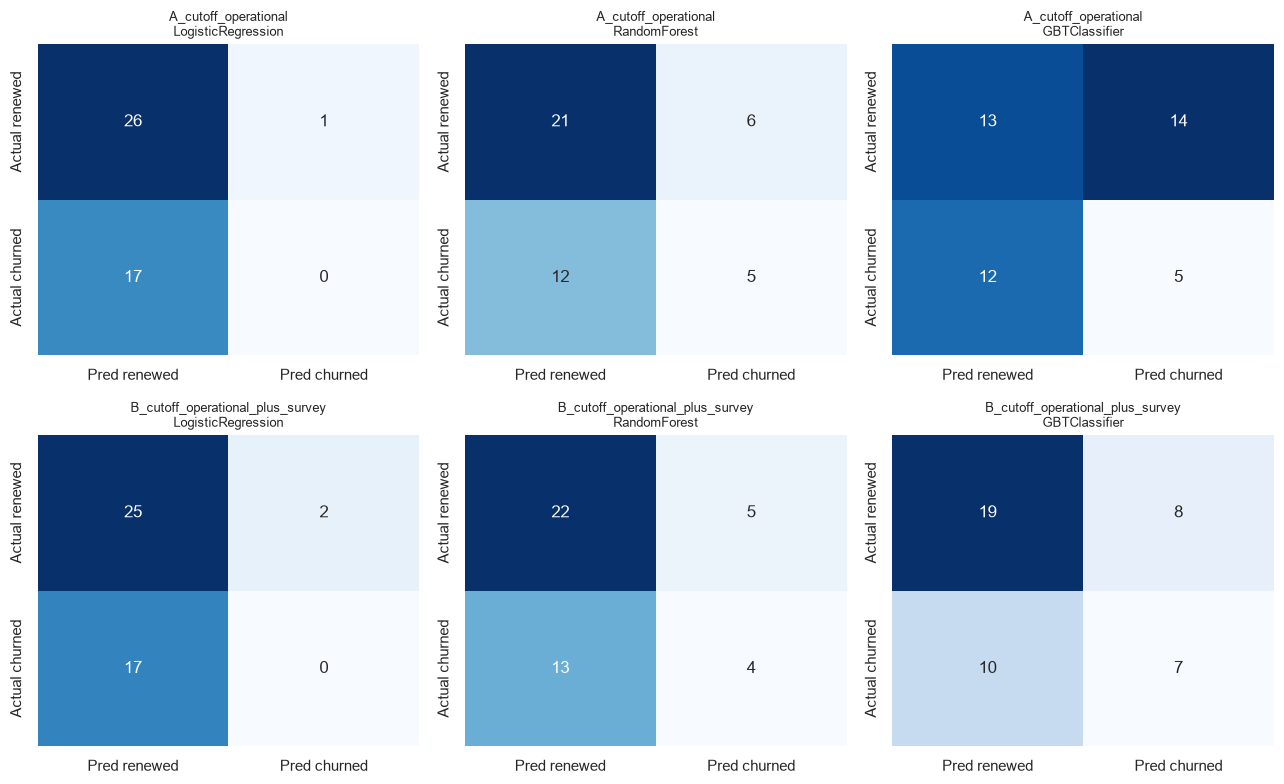

In [9]:
fig, axes = plt.subplots(len(CONFIGS), 3, figsize=(13, 4 * len(CONFIGS)))
for i, cfg_name in enumerate(CONFIGS):
    for j, model_name in enumerate(["LogisticRegression", "RandomForest", "GBTClassifier"]):
        r = results_df[(results_df.config == cfg_name) & (results_df.model == model_name)].iloc[0]
        cm = np.array([[r.TN, r.FP], [r.FN, r.TP]])
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[i, j],
                    xticklabels=["Pred renewed", "Pred churned"], yticklabels=["Actual renewed", "Actual churned"])
        axes[i, j].set_title(f"{cfg_name}\n{model_name}", fontsize=9)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrices.png", dpi=130)
plt.show()

## 9. Model comparison: A versus B, and against the leaky canonical result

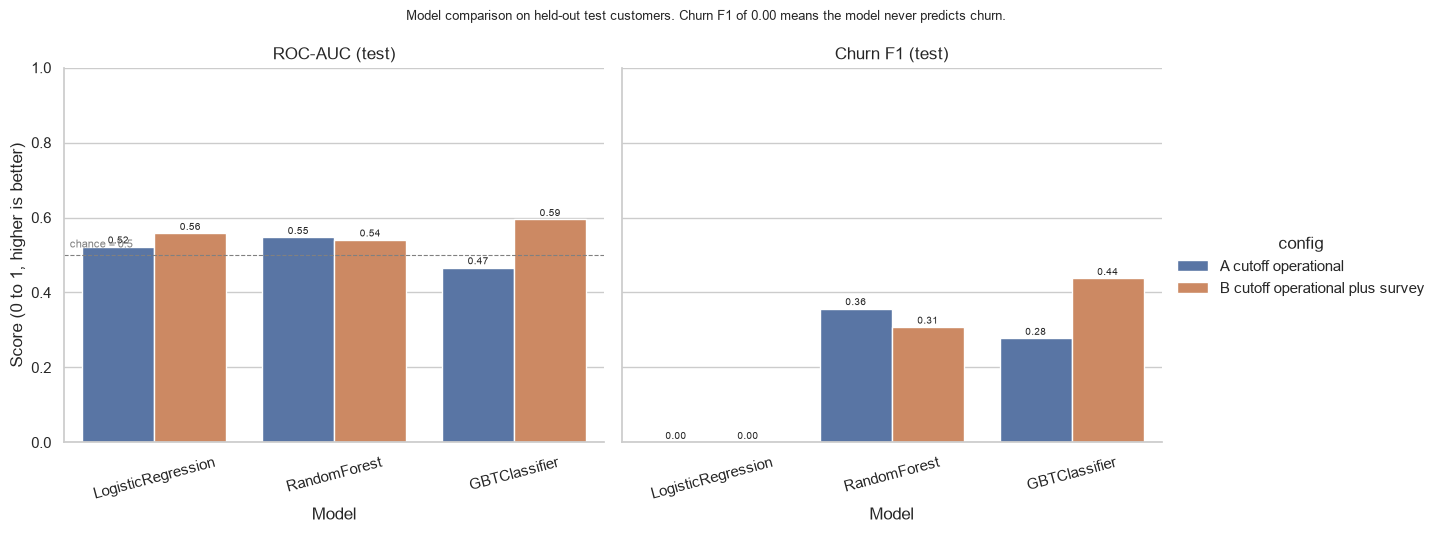

,model,canonical_cv_auc,canonical_test_auc,canonical_churn_f1,cutoff_cv_auc,cutoff_test_auc,cutoff_churn_f1
0,LogisticRegression,0.776,0.747,0.621,0.595,0.522,0.000
1,RandomForest,0.717,0.717,0.385,0.539,0.547,0.357
2,GBTClassifier,0.707,0.675,0.571,0.478,0.466,0.278


Canonical = full-window features (leaky). Cutoff = features up to start + 14 days.


In [10]:
metric_names = {"roc_auc": "ROC-AUC (test)", "churn_f1": "Churn F1 (test)"}
plot_df = results_df.melt(id_vars=["config", "model"], value_vars=["roc_auc", "churn_f1"], var_name="metric", value_name="value")
plot_df["metric"] = plot_df["metric"].map(metric_names)
plot_df["config"] = plot_df["config"].str.replace("_", " ")
g = sns.catplot(data=plot_df, x="model", y="value", hue="config", col="metric", kind="bar",
                height=4.8, aspect=1.25, sharey=True, legend_out=True)
g.set_titles("{col_name}")
g.set_axis_labels("Model", "Score (0 to 1, higher is better)")
g.set(ylim=(0, 1))
for ax in g.axes.flat:
    ax.tick_params(axis="x", labelrotation=15)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f", fontsize=7, padding=1)
g.axes.flat[0].axhline(0.5, ls="--", color="grey", lw=0.8)
g.axes.flat[0].text(0.01, 0.52, "chance = 0.5", color="grey", fontsize=8, transform=g.axes.flat[0].get_yaxis_transform())
g.figure.suptitle("Model comparison on held-out test customers. Churn F1 of 0.00 means the model never predicts churn.", y=1.04, fontsize=9)
g.savefig(OUTPUT_DIR / "model_comparison.png", dpi=130, bbox_inches="tight")
plt.show()

canonical = pd.read_csv(PROJECT / "outputs/ml/model_results.csv")
canon_best = canonical[canonical.config.str.startswith("A")][["model", "cv_roc_auc", "roc_auc", "churn_f1"]]
canon_best = canon_best.rename(columns={"cv_roc_auc": "canonical_cv_auc", "roc_auc": "canonical_test_auc", "churn_f1": "canonical_churn_f1"})
cut_best = results_df[results_df.config.str.startswith("A")][["model", "cv_roc_auc", "roc_auc", "churn_f1"]]
cut_best = cut_best.rename(columns={"cv_roc_auc": "cutoff_cv_auc", "roc_auc": "cutoff_test_auc", "churn_f1": "cutoff_churn_f1"})
comparison = canon_best.merge(cut_best, on="model")
display(comparison.round(3))
print("Canonical = full-window features (leaky). Cutoff = features up to start + 14 days.")

## 10. ROC curves

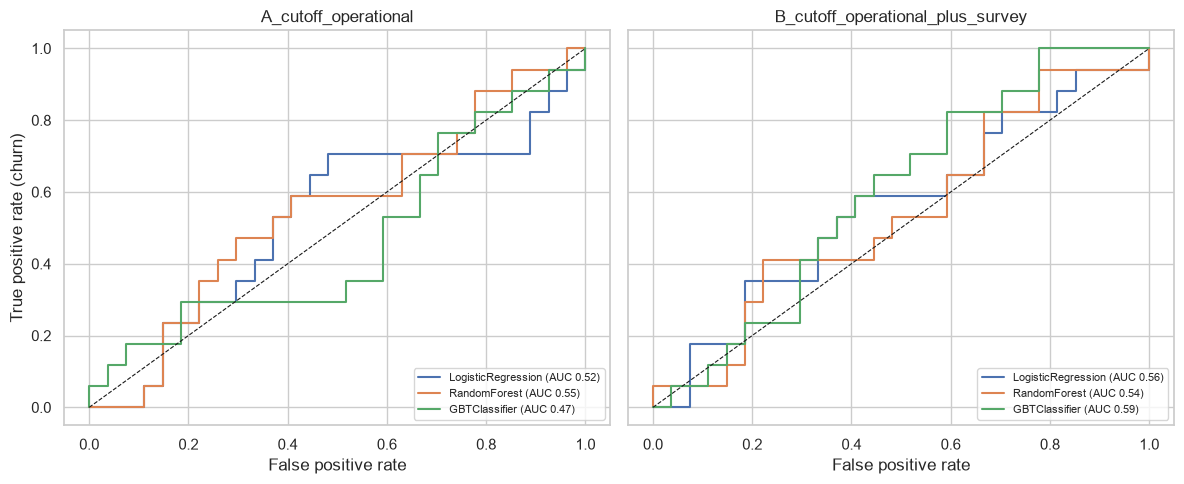

In [11]:
def roc_points(pred):
    p = pred.select(vector_to_array("probability")[1].alias("score"), F.col("churn_label").alias("y"))
    n_pos = p.filter(F.col("y") == 1.0).count()
    n_neg = p.count() - n_pos
    w = Window.orderBy(F.desc("score")).rowsBetween(Window.unboundedPreceding, Window.currentRow)
    cum = (p.withColumn("tp", F.sum("y").over(w))
            .withColumn("fp", F.sum(F.lit(1.0) - F.col("y")).over(w))
            .select((F.col("fp") / n_neg).alias("fpr"), (F.col("tp") / n_pos).alias("tpr"))
            .toPandas().sort_values(["fpr", "tpr"]))
    return [(0.0, 0.0)] + list(zip(cum["fpr"], cum["tpr"])) + [(1.0, 1.0)]

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, cfg_name in zip(axes, CONFIGS):
    for model_name in ["LogisticRegression", "RandomForest", "GBTClassifier"]:
        _, pred = fitted[(cfg_name, model_name)]
        fpr, tpr = zip(*roc_points(pred))
        auc = results_df[(results_df.config == cfg_name) & (results_df.model == model_name)].roc_auc.iloc[0]
        ax.plot(fpr, tpr, label=f"{model_name} (AUC {auc:.2f})")
    ax.plot([0, 1], [0, 1], "k--", linewidth=0.8)
    ax.set_title(cfg_name)
    ax.set_xlabel("False positive rate")
    ax.legend(loc="lower right", fontsize=8)
axes[0].set_ylabel("True positive rate (churn)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "roc_curves.png", dpi=130)
plt.show()

## 11. Final model selection, saving and test predictions

Selection uses **cross-validated** AUC only. The saved predictions cover the held-out test customers and are used by the dashboard.

In [12]:
best = results_df.sort_values("cv_roc_auc", ascending=False).iloc[0]
print("Selected by CV AUC:", best.config, "/", best.model, "| CV AUC", round(best.cv_roc_auc, 3), "| test AUC", round(best.roc_auc, 3))
best_cv_model, best_pred = fitted[(best.config, best.model)]
pipeline_path = MODEL_DIR / f"best_pipeline_{best.config}_{best.model}"
best_cv_model.bestModel.write().overwrite().save(str(pipeline_path))
print("Saved pipeline:", pipeline_path)

(best_pred.select("customer_id", "auto_renew", "churn_label", "prediction",
                  vector_to_array("probability")[1].alias("churn_probability"))
    .toPandas()
    .to_csv(OUTPUT_DIR / "test_predictions_selected_model.csv", index=False))
pd.DataFrame([{"selected_config": best.config, "selected_model": best.model,
               "pipeline_path": str(pipeline_path.relative_to(PROJECT))}]).to_csv(OUTPUT_DIR / "selected_model.csv", index=False)
print("Saved test predictions and selection metadata to", OUTPUT_DIR)

Selected by CV AUC: A_cutoff_operational / LogisticRegression | CV AUC 0.595 | test AUC 0.522


Saved pipeline: /Users/atchyuthkarri/7COM2005-Data-Engineering/PerfectPetClub/models/cutoff14/best_pipeline_A_cutoff_operational_LogisticRegression
Saved test predictions and selection metadata to /Users/atchyuthkarri/7COM2005-Data-Engineering/PerfectPetClub/outputs/ml_cutoff14


## 12. Conclusions

**Main result: with leakage removed, the models do not separate renewing from churning customers reliably.**

- **The earlier results were inflated by leakage.** Cross-validated AUC was 0.71 to 0.78 on the full-window features (`02`), and it falls to 0.48 to 0.60 with features that stop at start + 14 days.
- **No reliable signal in the first 14 days.** Every model's CV AUC is between 0.46 and 0.60, and test AUC between 0.47 and 0.60. With 44 test customers these are not distinguishable from chance. I have not formally tested this.
- **Selected model.** The rule picks Configuration A, Logistic Regression, on CV AUC (0.595). It predicts no churn at all (churn precision and recall 0.000), so it is not usable. This is what the selection rule gives on this data, not a model to deploy.
- **Survey (Configuration B) does not help consistently.** GBT reaches the highest test AUC (0.595) but the lowest CV AUC (0.456). That mismatch is noise, not evidence. Survey timing is also unknown.
- **Why the signal disappears.** Notebook `03` found that in the first 14 days churned customers averaged more orders than renewed ones (14.3 against 12.3). The full-window pattern came from the shorter windows of churned customers, not from early behaviour.

**Limits:** 221 customers, a 44-customer test set, churn as a proxy (`auto_renew = 0`), a single 14-day cutoff chosen before results, and no check against actual cancellation records.

**21-day check (done, notebooks 05 and 06):** a 21-day window gives the same answer, with CV AUC 0.50 to 0.55 and no reliable signal.

**Suggested next steps (not run):** a time-based holdout, the actual cancellation date if the source has it, and survey timestamps.

In [13]:
spark.stop()
print("SparkSession stopped.")

SparkSession stopped.
